In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
from dotenv import load_dotenv
import os
import re
import folium
import branca.colormap as cm
from pyproj import Transformer
from scipy.spatial import cKDTree


data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv") 

# ---------------------------------------------------------------------------
# 2. Data exploration
# ---------------------------------------------------------------------------

# Calculate the number of missing values per variable
missing = pd.DataFrame({
    "n_missing": data_realo.isna().sum(),
    "pct_missing": (data_realo.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES PER VARIABLE (sorted, highest first)")
print("=" * 70)
print(missing.to_string())

print(f"\nVariables with no missing values:   {(missing['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing['n_missing'] > 0).sum()}")
print(f"Variables completely empty (100%):  {(missing['pct_missing'] == 100).sum()}")

# Determine the datatype per variable
dtypes = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})

print("\n" + "=" * 70)
print("DATA TYPE PER VARIABLE (in file order)")
print("=" * 70)
print(dtypes.to_string())

print("\nNumber of variables per data type:")
print(dtypes["dtype"].value_counts().to_string())

# For now, we will not do anything about the missing values. The datatypes, 
# however, do need to be changed. 

# --- Convert variables to their appropriate datatypes -----------------------
# Empty cells are always treated as missing; they are never recoded (e.g. to 0 or False).

# Variables grouped by target datatype
admin_vars = ["addressId", "admin1Id", "admin1", "admin2Id", "admin2",
              "localityId", "locality", "subLocalityId", "subLocality",
              "districtId", "district", "postalCode", "niscode", "region"]
string_vars = ["marker"]
date_vars = ["firstListing", "lastListing", "certificateDate"]
category_vars = ["addressType", "housingType", "secondaryHousingType",
                 "detachment", "way", "heatingType", "floodProneLocation",
                 "buildingCondition"]
bool_vars = ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels",
             "hasSwimmingPool", "hasSingleGlass", "hasDoubleGlass",
             "hasCentralHeating", "hasSolarBoiler"]
int_vars = ["numberOfSides", "numberOfBedrooms", "numberOfBathrooms",
            "numberOfToilets", "numberOfFloors", "floor", "buildYear",
            "renovationYear"]
float_vars = ["lon", "lat", "price", "initialPrice", "habitableArea",
              "terraceArea", "buildingArea", "estimatedArea",
              "estimatedGardenArea", "energyConsumption", "eLevel", "kLevel",
              "distanceToNearestCenter", "busStopDistance",
              "trainStopDistance", "schoolDistance", "mScore",
              "greenCoverage", "cadastralIncome"]



C:\Users\fedra\AppData\Local\Temp\ipykernel_22608\2859703918.py:15: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv")



MISSING VALUES PER VARIABLE (sorted, highest first)
                         n_missing  pct_missing
kLevel                      530955        98.26
renovationYear              524287        97.03
eLevel                      515568        95.42
hasSingleGlass              499660        92.47
hasSolarBoiler              488782        90.46
hasCentralHeating           441196        81.65
terraceArea                 379809        70.29
estimatedGardenArea         375661        69.52
hasSwimmingPool             360996        66.81
certificateDate             347557        64.32
floor                       346416        64.11
cadastralIncome             304651        56.38
detachment                  299795        55.48
hasDoubleGlass              202682        37.51
numberOfFloors              197253        36.51
numberOfSides               183058        33.88
buildingArea                163420        30.24
energyConsumption           158073        29.25
buildingCondition           155443 


DATATYPE CONVERSION
No values were lost in the conversion.

Datatypes after conversion:
addressId                          string
admin1Id                           string
admin1                             string
admin2Id                           string
admin2                             string
localityId                         string
locality                           string
subLocalityId                      string
subLocality                        string
districtId                         string
district                           string
postalCode                         string
niscode                            string
region                             string
lon                               Float64
lat                               Float64
addressType                      category
firstListing               datetime64[ns]
lastListing                datetime64[ns]
housingType                      category
secondaryHousingType             category
detachment                   

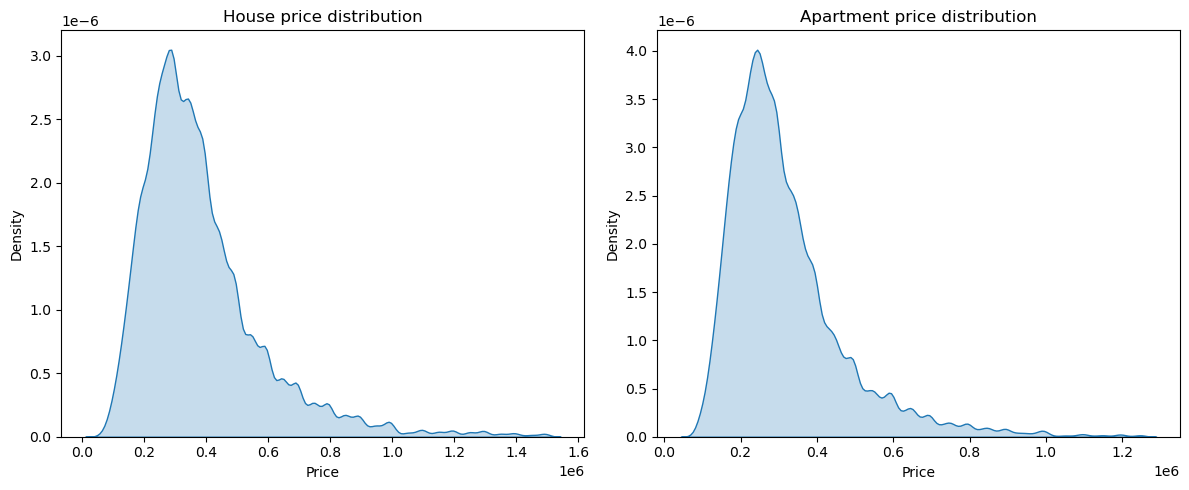

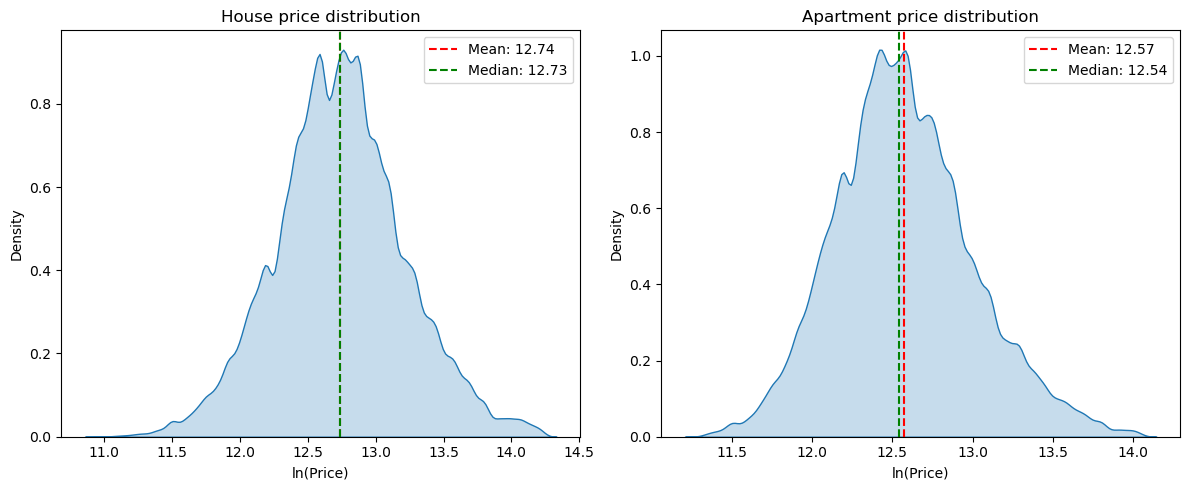

year_last    2015.0  2016.0  2017.0  2018.0  2019.0  2020.0  2021.0  2022.0  \
housingType                                                                   
APARTMENT    2520.0  2641.0  2774.0  2854.0  3099.0  3200.0  3258.0  3332.0   
HOUSE        1679.0  1745.0  1771.0  1838.0  1882.0  2018.0  2094.0  2187.0   

year_last    2023.0  2024.0  2025.0  2026.0  
housingType                                  
APARTMENT    3406.0  3499.0  3506.0  3538.0  
HOUSE        2251.0  2273.0  2310.0  2360.0  
9763 rows without a factor


C:\Users\fedra\AppData\Local\Temp\ipykernel_22608\2843244159.py:166: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  level = df.groupby(['housingType', 'year_last'])['pm2'].mean().unstack('year_last')


In [37]:
# Step 1: Keep track of missing values before conversion
n_missing_before = data_realo.isna().sum()

# Step 2: convert each group
for var in admin_vars + string_vars:
    col = data_realo[var]
    # Numeric codes read as floats (e.g. 9000.0) are first made whole numbers,
    # so that the string becomes "9000" and not "9000.0"
    if pd.api.types.is_float_dtype(col):
        col = col.astype("Int64")
    data_realo[var] = col.astype("string").str.strip()

for var in date_vars:
    data_realo[var] = pd.to_datetime(data_realo[var], errors="coerce")

for var in category_vars:
    data_realo[var] = data_realo[var].astype("string").str.strip().astype("category")

bool_map = {"1": True, "0": False, "1.0": True, "0.0": False,
            "true": True, "false": False, "yes": True, "no": False}
for var in bool_vars:
    data_realo[var] = (data_realo[var].astype("string").str.strip().str.lower()
                       .map(bool_map).astype("boolean"))

for var in float_vars:
    data_realo[var] = pd.to_numeric(data_realo[var], errors="coerce").astype("Float64")

for var in int_vars:
    col = pd.to_numeric(data_realo[var], errors="coerce")
    non_whole = (col.notna() & (col % 1 != 0)).sum()
    if non_whole > 0:
        # Do not silently round: keep as Float64 and flag it
        print(f"WARNING: {var} has {non_whole} non-whole values; kept as Float64.")
        data_realo[var] = col.astype("Float64")
    else:
        data_realo[var] = col.astype("Int64")

# Step 3: check that the conversion did not create new missing values
# (a value that could not be converted, e.g. text in a numeric column, becomes <NA>)
n_missing_after = data_realo.isna().sum()
new_missing = (n_missing_after - n_missing_before)
new_missing = new_missing[new_missing > 0]

print("\n" + "=" * 70)
print("DATATYPE CONVERSION")
print("=" * 70)
if new_missing.empty:
    print("No values were lost in the conversion.")
else:
    print("Values that could not be converted and are now missing:")
    print(new_missing.to_string())

print("\nDatatypes after conversion:")
print(data_realo.dtypes.astype(str).to_string())

dtypes_after_conversion = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})
print("\nNumber of variables per data type:")
print(dtypes_after_conversion["dtype"].value_counts().to_string())



# --- Observations per region, split by housing type ------------------------
# Number of observations per unique value of admin1 and admin2, split by
# housingType (i.e. APARTMENT vs HOUSE).
for region_var in ["admin1", "admin2"]:
    counts = pd.crosstab(
        data_realo[region_var].astype(object),
        data_realo["housingType"].astype(object),
        margins=True, margins_name="Total",
    )
    print("\n" + "=" * 70)
    print(f"NUMBER OF OBSERVATIONS PER {region_var.upper()} AND HOUSING TYPE")
    print("=" * 70)
    print(counts.to_string())
    
# --- Remove all observations with admin2 == "Brugge" ------------------------
# We remove these as Brugge is neither part of Oost-Vlaanderen nor Brussels 
data_realo = data_realo[data_realo["admin2"] != "Brugge"]

# ---------------------------------------------------------------------------
# 3. Plot price distribution
# ---------------------------------------------------------------------------

# Combine year and month into a single column
data_realo['firstListing year_month'] = data_realo['firstListing'].dt.to_period('M')
data_realo['lastListing year_month'] = data_realo['lastListing'].dt.to_period('M')

# Let's see what the distribution of 'Price' looks like for both apartments and houses
# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot KDE for 'HOUSE' on the left subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'HOUSE'], x='price', ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('Price')
ax1.set_ylabel('Density')

# Plot KDE for 'APARTMENT' on the right subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'APARTMENT'], x='price', ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('Price')
ax2.set_ylabel('Density')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# This data seems to be log-normally distributed. Let's do a log-transform and 
# plot again

data_realo["ln(price)"] = np.log(data_realo["price"]) 
data_realo["ln(initialPrice)"] = np.log(data_realo["initialPrice"]) 

# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: HOUSE 
house_data = data_realo[data_realo['housingType'] == 'HOUSE']['ln(price)']
sns.kdeplot(data=house_data, ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('ln(Price)')
ax1.set_ylabel('Density')

# Calculate mean and median for HOUSE
mean_house = house_data.mean()
median_house = house_data.median()

# Add vertical lines for mean and median
ax1.axvline(mean_house, color='red', linestyle='--', label=f'Mean: {mean_house:.2f}')
ax1.axvline(median_house, color='green', linestyle='--', label=f'Median: {median_house:.2f}')
ax1.legend()

# Right subplot: APARTMENT 
apartment_data = data_realo[data_realo['housingType'] == 'APARTMENT']['ln(price)']
sns.kdeplot(data=apartment_data, ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('ln(Price)')
ax2.set_ylabel('Density')

# Calculate mean and median for APARTMENT
mean_apartment = apartment_data.mean()
median_apartment = apartment_data.median()

# Add vertical lines for mean and median
ax2.axvline(mean_apartment, color='red', linestyle='--', label=f'Mean: {mean_apartment:.2f}')
ax2.axvline(median_apartment, color='green', linestyle='--', label=f'Median: {median_apartment:.2f}')
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


data_realo = data_realo[data_realo["estimatedArea"]!= np.nan]
data_realo["price/m2"] = data_realo["price"] / data_realo["estimatedArea"]
data_prices = data_realo.copy()

base_year = 2026

df = data_realo
df['pm2'] = df['price'] / df['habitableArea']
df['year_last'] = pd.to_datetime(df['lastListing'], errors='coerce').dt.year
df['year_first'] = pd.to_datetime(df['firstListing'], errors='coerce').dt.year

# mean price/m2 per housing type per year
level = df.groupby(['housingType', 'year_last'])['pm2'].mean().unstack('year_last')

# factor = 2026 level / level of that year
factor = level.div(level[base_year], axis=0).rdiv(1)   # = level[base_year] / level

# look up the factor for every listing
def get_factor(year_col):
    idx = pd.MultiIndex.from_arrays([df['housingType'], df[year_col]])
    return pd.Series(factor.stack().reindex(idx).to_numpy(), index=df.index)

f_last = get_factor('year_last')
f_first = get_factor('year_first')

df['inflation_factor'] = f_last
df['price_adj'] = df['price'] * f_last
df['initialPrice_adj'] = df['initialPrice'] * f_first
df['ln(price_adj)'] = df['ln(price)'] + np.log(f_last)
df['ln(initialPrice_adj)'] = df['ln(initialPrice)'] + np.log(f_first)
df['price/m2hab_adj'] = df['price_adj'] / df['habitableArea']

data_prices_adj = df

print(level.round(0))
print(f_last.isna().sum(), "rows without a factor")

# --- Function: plot the evolution of house prices, CPI and gross income -----


In [18]:
data_realo['postalCode'].unique()

<StringArray>
['9900', '9000', '1050', '9240', '9600', '1180', '1030', '1020', '9280',
 '1090',
 ...
 '9772', '9401', '9981', '9521', '9771', '9932', '9931', '9403', '9982',
 '9571']
Length: 137, dtype: string

In [38]:
data_realo['postalCode']

1         9900
2         9000
6         1050
7         9240
8         9600
          ... 
540334    9620
540335    9255
540337    9870
540338    9870
540341    9340
Name: postalCode, Length: 443619, dtype: string

In [41]:
data_realo

,addressId,admin1Id,admin1,admin2Id,admin2,localityId,locality,subLocalityId,subLocality,districtId,...,price/m2,pm2,year_last,year_first,inflation_factor,price_adj,initialPrice_adj,ln(price_adj),ln(initialPrice_adj),price/m2hab_adj
1,4148489,5388851,Oost-Vlaanderen,5389060,Eeklo,5387914,Eeklo,5194725,Eeklo,5204854,...,1712.962963,1850.0,2015.0,2015,1.403947,259730.153569,259730.153569,12.467399,12.467399,2597.301536
2,4382733,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205161,...,352.564103,1946.902655,2015.0,2015,1.403947,308868.290731,308868.290731,12.64067,12.64067,2733.347706
6,106279,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5387917,Ixelles,5194013,Ixelles,5198978,...,34.404903,4000.0,2015.0,2015,1.403947,449262.968336,449262.968336,13.015364,13.015364,5615.787104
7,4130941,5388851,Oost-Vlaanderen,5389059,Dendermonde,5388346,Zele,5194720,Zele,5204826,...,208.604954,2222.222222,2015.0,2015,1.403947,224631.484168,224631.484168,12.322216,12.322216,3119.881725
8,4502906,5388851,Oost-Vlaanderen,5389062,Oudenaarde,5388219,Ronse,5194837,Ronse,5205701,...,2202.932331,2202.932331,2015.0,2015,1.403947,411342.365915,411342.365915,12.927181,12.927181,3092.799744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540334,5760080,5388851,Oost-Vlaanderen,5389058,Aalst,5388354,Zottegem,<NA>,<NA>,<NA>,...,553.412621,2478.326087,2026.0,2025,1.000000,456012.0,467485.054927,13.030274,13.055123,2478.326087
540335,5760047,5388851,Oost-Vlaanderen,5389059,Dendermonde,5387861,Buggenhout,<NA>,<NA>,<NA>,...,1203.614458,3009.036145,2026.0,2025,1.000000,499500.0,505705.124443,13.121363,13.133709,3009.036145
540337,5760104,5388851,Oost-Vlaanderen,5389061,Gent,5388357,Zulte,<NA>,<NA>,<NA>,...,2378.378378,3259.259259,NaN,2026,NaN,<NA>,352000.0,<NA>,12.771386,<NA>
540338,5760104,5388851,Oost-Vlaanderen,5389061,Gent,5388357,Zulte,<NA>,<NA>,<NA>,...,1614.893617,3513.888889,NaN,2026,NaN,<NA>,377000.0,<NA>,12.84,<NA>


In [58]:
data_realo[data_realo['admin2']=='Gent']['locality'].unique()

<StringArray>
[              'Gent',             'Deinze',  'Nazareth-De Pinte',
    'Merelbeke-Melle',            'Evergem',             'Aalter',
         'Oosterzele',       'Destelbergen',             'Gavere',
          'Lochristi',              'Zulte', 'Sint-Martens-Latem',
           'Lievegem',            'Lokeren']
Length: 14, dtype: string

In [45]:
data_realo[data_realo['postalCode']=='9050']

,addressId,admin1Id,admin1,admin2Id,admin2,localityId,locality,subLocalityId,subLocality,districtId,...,price/m2,pm2,year_last,year_first,inflation_factor,price_adj,initialPrice_adj,ln(price_adj),ln(initialPrice_adj),price/m2hab_adj
593,4354427,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205261,...,325.884544,1966.292135,2015.0,2015,1.403947,245690.685809,245690.685809,12.411829,12.411829,2760.569503
797,4326213,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205260,...,611.374408,2580.0,2015.0,2015,1.403947,181109.13411,181109.13411,12.106855,12.106855,3622.182682
1063,4385301,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194772,Gentbrugge,5205251,...,690.751445,1991.666667,2015.0,2015,1.403947,167771.639738,167771.639738,12.030359,12.030359,2796.193996
1282,4262127,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205260,...,120.815138,1627.45098,2015.0,2015,1.403947,233055.164824,233055.164824,12.35903,12.35903,2284.854557
1531,4386096,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205266,...,929.648241,1887.755102,2015.0,2015,1.403947,259730.153569,259730.153569,12.467399,12.467399,2650.307689
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
537276,4276814,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205267,...,2200.0,2715.189873,2025.0,2025,1.021627,438277.774518,438277.774518,12.990608,12.990608,2773.909965
537277,4306691,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194773,Ledeberg,5205267,...,4397.058824,2392.0,2026.0,2025,1.000000,299000.0,305466.327694,12.608199,12.629595,2392.0
539078,4328013,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194772,Gentbrugge,5205257,...,708.013172,2433.962264,2019.0,2019,1.253660,808610.644865,808610.644865,13.603073,13.603073,3051.360924
539079,4299387,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194772,Gentbrugge,5205257,...,670.600858,2976.190476,2025.0,2025,1.021627,638516.571267,638516.571267,13.366903,13.366903,3040.555101
